# Homework 4: Evaluation Metrics for Classification

This notebook follows the homework questions. Code cells are left blank for you to complete. The dataset is the 2026 lead-scoring release, and the target is `converted`. Relative to this notebook, the dataset path is `../../data/course_lead_scoring_2026.csv`.

See [homework.md](homework.md) for the full instructions and submission details.

## 1. Load, Inspect, and Prepare the Data

Record basic dataset information and check for missing values. Handle missing feature values as required, then split the data into training, validation, and test sets using the specified `random_state=1`.

In [39]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from urllib.request import urlretrieve

pd.set_option('display.max_columns', None)
%matplotlib inline

In [8]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
data_path = Path.cwd().parent.parent / 'data' / 'course_lead_scoring_2026.csv'
if not data_path.exists():
    urlretrieve(data, data_path)

df = pd.read_csv(data_path)

print(f'Dataset: {data_path.resolve()}')
print(f'Shape: {df.shape}')
df.head()

Dataset: C:\Users\yanji\Projects\machine-learning-zoomcamp\cohorts\2026\data\course_lead_scoring_2026.csv
Shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


check for missing values

In [12]:
df.info()
print('\nMissing values:')
df.isna().sum().sort_values(ascending=False)

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB

Missing values:


annual_income               369
industry                    240
location                    208
employment_status           194
lead_source                 148
lead_score                   35
number_of_courses_viewed      0
interaction_count             0
converted                     0
dtype: int64

If there are missing values:
For categorical features, replace them with 'NA'
For numerical features, replace with with 0.0

In [16]:
target = 'converted'
categorical_features = df.select_dtypes(include='object').columns.drop(target, errors='ignore').tolist()
numerical_features = df.select_dtypes(include='number').columns.drop(target, errors='ignore').tolist()
print('Categorical features:', categorical_features)
print('Numerical features:', numerical_features)
for feature in categorical_features:
    df[feature] = df[feature].fillna('NA')
for feature in numerical_features:
    df[feature] = df[feature].fillna(0.0)
print('Remaining missing values:', int(df.isna().sum().sum()))

Categorical features: ['lead_source', 'industry', 'employment_status', 'location']
Numerical features: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
Remaining missing values: 0


C:\Users\yanji\AppData\Local\Temp\ipykernel_40416\2354565717.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include='object').columns.drop(target, errors='ignore').tolist()


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

Split the data into 3 parts

In [ ]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [19]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

del df_train[target]
del df_val[target]
del df_test[target]

## 2. Question 1: ROC AUC Feature Importance

For each numerical feature, compute its AUC on the training set using `converted` as the ground-truth target. If a feature's AUC is below `0.5`, reverse its direction before comparing the candidate features.

In [22]:
from sklearn.metrics import roc_auc_score
auc_score = {}
for feature in numerical_features:
    score = roc_auc_score(y_train, df_train[feature])
    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[feature])
    auc_score[feature] = score
dict(sorted(auc_score.items(), key=lambda item: item[1], reverse=True))

{'lead_score': 0.7882254810906102,
 'interaction_count': 0.7649203047563227,
 'number_of_courses_viewed': 0.7229894623989618,
 'annual_income': 0.6081977776250831}

**Answer:lead_score**

## 3. Question 2: Train the Model and Evaluate Validation AUC

Apply one-hot encoding with `DictVectorizer` and train logistic regression with the parameters specified in the homework. Compute the ROC AUC on the validation set and round it to three decimal places.

In [24]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical_features + numerical_features].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical_features + numerical_features].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [25]:
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
roc_auc_score(y_val, y_pred)


0.7318222288173319

**Answer:0.732**

## 4. Question 3: Precision-Recall Curves

Compute precision and recall at thresholds from `0.00` to `1.00` in steps of `0.01`, then plot both curves. Ignore thresholds where both metrics are zero. Record the threshold where the absolute difference between precision and recall is smallest.

In [29]:
thresholds = np.linspace(0, 1, 101)
scores = []
for t in thresholds:
    actual_positive = (y_val == 1)
    predicted_positive = (y_pred >= t)
    actual_negative = (y_val == 0)
    predicted_negative = (y_pred < t)
    tp = (actual_positive & predicted_positive).sum()
    fp = (actual_negative & predicted_positive).sum()
    tn = (actual_negative & predicted_negative).sum()
    fn = (actual_positive & predicted_negative).sum()
    scores.append((t, tp, fp, tn, fn))
columns = ['threshold', 'tp', 'fp', 'tn', 'fn']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores['recall'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fn'])
df_scores['precision'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fp'])

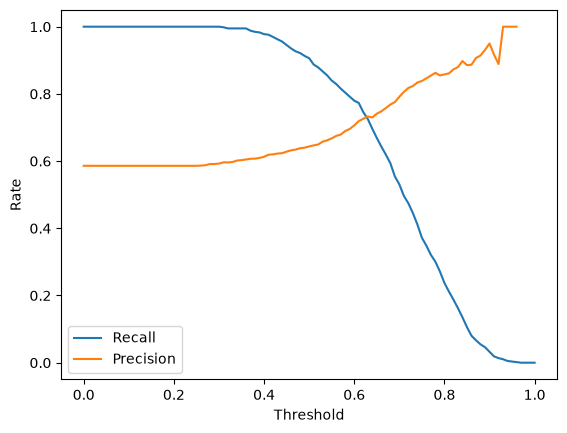

In [30]:
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.xlabel('Threshold')
plt.ylabel('Rate')
plt.legend()
plt.show()

**Answer:0.63**

## 5. Question 4: F1 Score and Optimal Threshold

Compute F1 at each threshold using the same range and step size. Examine how F1 changes with the threshold and record the threshold where F1 is highest.

In [32]:
precision = df_scores['precision'].fillna(0)
recall = df_scores['recall']
df_scores['f1'] = (2 * precision * recall).div(precision + recall).fillna(0)
df_scores.loc[df_scores['f1'].idxmax(), ['threshold', 'f1']]

threshold    0.410000
f1           0.757616
Name: 41, dtype: float64

**Answer:** 0.41

## 6. Question 5: 5-Fold Cross-Validation

Use the specified `KFold` configuration to train the same logistic regression model across five folds of `df_full_train`. Record the validation ROC AUC for each fold and calculate the standard deviation of the scores.

In [33]:
from sklearn.model_selection import KFold

In [34]:
!pip install tqdm
from tqdm.auto import tqdm


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
def cross_validate_auc(data, target, C=1.0, n_splits=5, random_state=1):
    scores = []
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    for train_idx, val_idx in kfold.split(data):
        train_fold = data.iloc[train_idx]
        val_fold = data.iloc[val_idx]
        y_train_fold = train_fold[target].values
        y_val_fold = val_fold[target].values
        X_train_fold = train_fold.drop(columns=[target])
        X_val_fold = val_fold.drop(columns=[target])

        dv, model = train(X_train_fold, y_train_fold, C=C)
        y_pred_fold = predict(X_val_fold, dv, model)
        scores.append(roc_auc_score(y_val_fold, y_pred_fold))

    return np.array(scores)

scores = cross_validate_auc(df_full_train, target)
for score in scores:
    print(f'ROC AUC: {score:.3f}')
print(f'Mean ROC AUC: {scores.mean():.3f} ± {scores.std():.3f}')

ROC AUC: 0.731
ROC AUC: 0.730
ROC AUC: 0.736
ROC AUC: 0.741
ROC AUC: 0.721
Mean ROC AUC: 0.732 ± 0.007


**Answer:0.007**

## 7. Question 6: Hyperparameter Tuning with C

Using the three `C` values and the same five-fold configuration specified in the homework, record the mean ROC AUC and standard deviation for each value, rounded to three decimal places. Apply the homework's tie-breaking rules.

In [40]:
for c in tqdm([0.000001, 0.001, 1]):
    scores = cross_validate_auc(df_full_train, target, C=c)
    print(f'C={c}: Mean ROC AUC: {scores.mean():.3f} ± {scores.std():.3f}')

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06: Mean ROC AUC: 0.617 ± 0.019
C=0.001: Mean ROC AUC: 0.749 ± 0.010
C=1: Mean ROC AUC: 0.732 ± 0.007


**Answer:0.001**